Epoch 1/100
51/51 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - accuracy: 0.4948 - auc: 0.4946 - loss: 0.9437 - val_accuracy: 0.5788 - val_auc: 0.5659 - val_loss: 0.7717
Epoch 2/100
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.5102 - auc: 0.5074 - loss: 0.8853 - val_accuracy: 0.5591 - val_auc: 0.5898 - val_loss: 0.7713
Epoch 3/100
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.5237 - auc: 0.5491 - loss: 0.8348 - val_accuracy: 0.5591 - val_auc: 0.5988 - val_loss: 0.7747
Epoch 4/100
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.5447 - auc: 0.5664 - loss: 0.8122 - val_accuracy: 0.5443 - val_auc: 0.6046 - val_loss: 0.7717
Epoch 5/100
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5336 - auc: 0.5523 - loss: 0.8095 - val_accuracy: 0.5443 - val_auc: 0.6107 - val_loss: 0.7651
Epoch 6/100
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.5490 - auc: 0.5820 - loss: 0.7947 - val_accuracy: 0.5468 - val_auc: 0.6093 - val_loss: 0.7633
Epoch 7/100
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 9

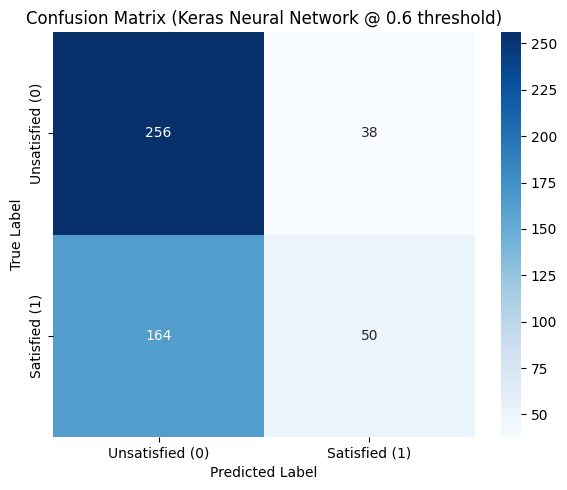

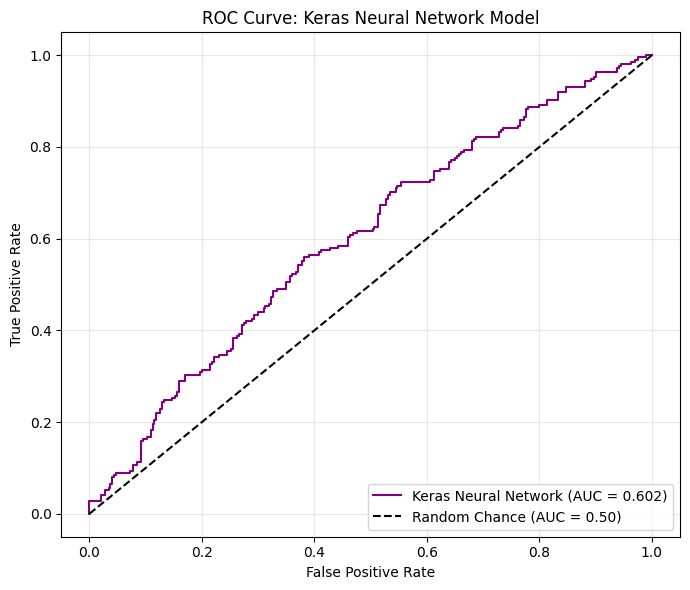

In [ ]:
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    brier_score_loss,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    roc_curve
)
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt
import seaborn as sns

dfraw = pd.read_csv('gss2024_onet_cleaned_v2.csv')

y = (dfraw['satjob'] == 1).astype(int)

base_features_A0 = [
    'age', 'sex', 'race', 'hispanic', 'born', 'educ',
    'marital', 'childs', 'region', 'union1', 'wrkstat',
    'wrkslf', 'hrs1', 'weekswrk', 'realrinc'
]
features_A1 = base_features_A0 + ['prestg10', 'sei10']
features_B = features_A1 + [
    'Achievement', 'Independence', 'Recognition',
    'Relationships', 'Support', 'Working Conditions', 'job_zone'
]

X = dfraw[features_A1].copy()

if 'realrinc' in X.columns:
    X['realrinc'] = np.log1p(X['realrinc'].clip(lower=0))

numeric_cols = X.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median', add_indicator=True)),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_cols),
    ('cat', categorical_transformer, categorical_cols)
])

X_processed = preprocessor.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_processed, y, test_size=0.20, random_state=42, stratify=y
)

model = Sequential([
    tf.keras.Input(shape=(X_train.shape[1],)),
    Dense(64, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.001)),
    BatchNormalization(),
    Dropout(0.4),
    Dense(32, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.001)),
    BatchNormalization(),
    Dropout(0.3),
    Dense(16, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.001)),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
)

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True
)

neg_count = np.sum(y_train == 0)
pos_count = np.sum(y_train == 1)
total = len(y_train)
class_weight = {
    0: (1 / neg_count) * (total / 2.0),
    1: (1 / pos_count) * (total / 2.0)
}

history = model.fit(
    X_train, y_train,
    validation_split=0.20,
    epochs=100,
    batch_size=32,
    class_weight=class_weight,
    callbacks=[early_stopping],
    verbose=1
)

y_pred_prob = model.predict(X_test).ravel()
test_auc = roc_auc_score(y_test, y_pred_prob)
test_pr_auc = average_precision_score(y_test, y_pred_prob)
test_brier = brier_score_loss(y_test, y_pred_prob)

print(f"\n--- Final Keras Test Set Evaluation ---")
print(f"Test ROC-AUC:   {test_auc:.4f}")
print(f"Test PR-AUC:    {test_pr_auc:.4f}")
print(f"Test Brier:     {test_brier:.4f}")

y_pred_binary = (y_pred_prob >= 0.6).astype(int)
cm_keras = confusion_matrix(y_test, y_pred_binary)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_keras,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Unsatisfied (0)', 'Satisfied (1)'],
    yticklabels=['Unsatisfied (0)', 'Satisfied (1)']
)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix (Keras Neural Network @ 0.6 threshold)')
plt.tight_layout()
plt.show()

fpr_keras, tpr_keras, _ = roc_curve(y_test, y_pred_prob)
plt.figure(figsize=(7, 6))
plt.plot(fpr_keras, tpr_keras, label=f'Keras Neural Network (AUC = {test_auc:.3f})', color='purple')
plt.plot([0, 1], [0, 1], 'k--', label='Random Chance (AUC = 0.50)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve: Keras Neural Network Model')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

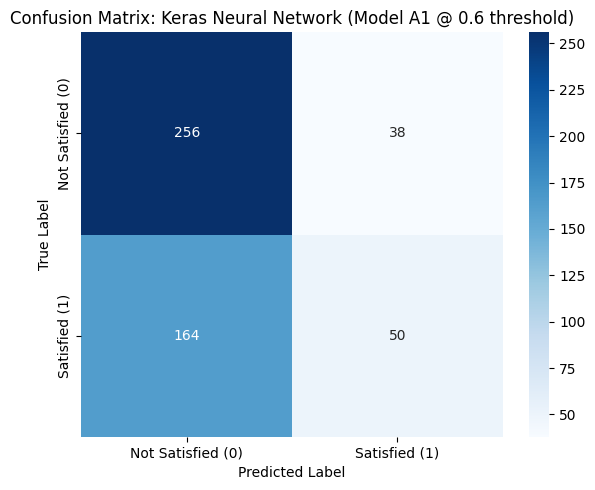

Model A1 Test ROC-AUC:   0.6019
Model A1 Test PR-AUC:    0.5157
Model A1 Test Brier Score: 0.2452


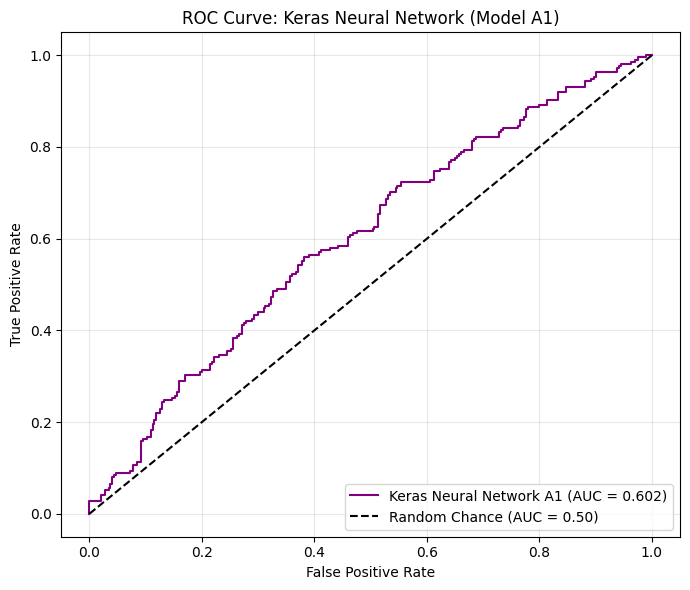

In [ ]:
y_pred_binary_A1 = (y_pred_prob >= 0.6).astype(int)
cm_A1 = confusion_matrix(y_test, y_pred_binary_A1)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_A1,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Satisfied (0)', 'Satisfied (1)'],
    yticklabels=['Not Satisfied (0)', 'Satisfied (1)']
)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix: Keras Neural Network (Model A1 @ 0.6 threshold)')
plt.tight_layout()
plt.show()

print(f"Model A1 Test ROC-AUC:   {test_auc:.4f}")
print(f"Model A1 Test PR-AUC:    {test_pr_auc:.4f}")
print(f"Model A1 Test Brier Score: {test_brier:.4f}")

fpr_keras, tpr_keras, _ = roc_curve(y_test, y_pred_prob)
plt.figure(figsize=(7, 6))
plt.plot(fpr_keras, tpr_keras, label=f'Keras Neural Network A1 (AUC = {test_auc:.3f})', color='purple')
plt.plot([0, 1], [0, 1], 'k--', label='Random Chance (AUC = 0.50)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve: Keras Neural Network (Model A1)')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()